In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve


In [3]:
df = pd.read_csv("AI Job Market Dataset.csv")
df

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10340,10341,Data Engineer,Startup,Technology,USA,Onsite,Entry,2,PhD,1,0,1,0,1,76426,4,2023,Low,4
10341,10342,Data Analyst,Medium,Healthcare,Australia,Hybrid,Entry,10,Master,1,1,0,0,1,61233,9,2024,Medium,6
10342,10343,Machine Learning Engineer,Startup,Education,Germany,Hybrid,Entry,4,PhD,0,0,0,1,0,103681,3,2026,Low,4
10343,10344,Data Engineer,MNC,E-commerce,Canada,Hybrid,Mid,5,PhD,1,1,1,0,0,112895,12,2024,High,9


In [4]:
df.shape

(10345, 19)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   job_id                10345 non-null  int64 
 1   job_title             10345 non-null  object
 2   company_size          10345 non-null  object
 3   company_industry      10345 non-null  object
 4   country               10345 non-null  object
 5   remote_type           10345 non-null  object
 6   experience_level      10345 non-null  object
 7   years_experience      10345 non-null  int64 
 8   education_level       10345 non-null  object
 9   skills_python         10345 non-null  int64 
 10  skills_sql            10345 non-null  int64 
 11  skills_ml             10345 non-null  int64 
 12  skills_deep_learning  10345 non-null  int64 
 13  skills_cloud          10345 non-null  int64 
 14  salary                10345 non-null  int64 
 15  job_posting_month     10345 non-null

In [6]:
df.describe()

,job_id,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.00000,10345.000000,10345.000000,10345.00000
mean,5173.000000,6.950507,0.493088,0.503045,0.507878,0.498018,0.511455,113438.22726,6.502465,2023.000387,5.00406
std,2986.488601,4.320054,0.499976,0.500015,0.499962,0.500020,0.499893,31389.20106,3.473441,1.996856,2.58382
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45083.00000,1.000000,2020.000000,1.00000
25%,2587.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89715.00000,4.000000,2021.000000,3.00000
50%,5173.000000,7.000000,0.000000,1.000000,1.000000,0.000000,1.000000,113082.00000,6.000000,2023.000000,5.00000
75%,7759.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,134894.00000,10.000000,2025.000000,7.00000
max,10345.000000,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,204143.00000,12.000000,2026.000000,9.00000


In [8]:
df.duplicated().sum()

np.int64(0)

In [10]:
#EXPLORATORY DATA ANALYSIS
 #Job Title Distribution

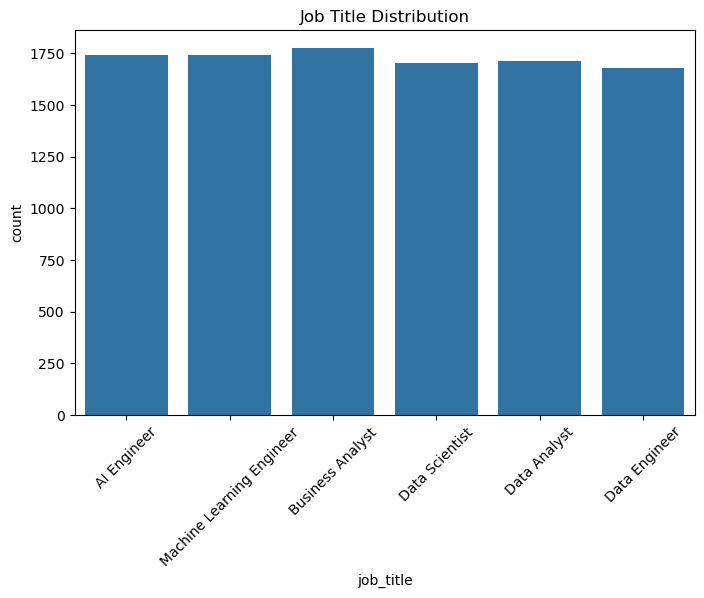

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="job_title")
plt.xticks(rotation=45)
plt.title("Job Title Distribution")
plt.show()

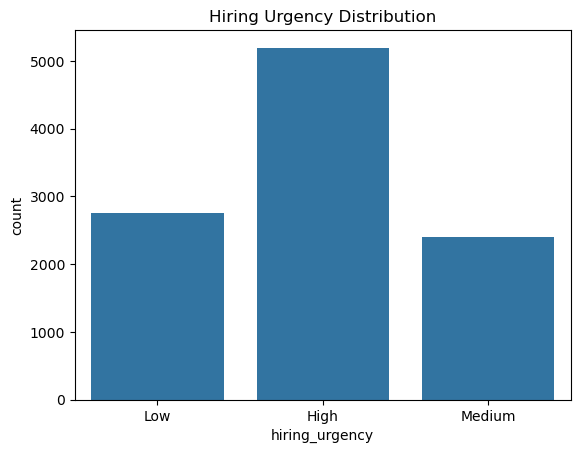

In [12]:
#HIRING URGENCY DISTRIBUTION

sns.countplot(data=df, x="hiring_urgency")
plt.title("Hiring Urgency Distribution")
plt.show()

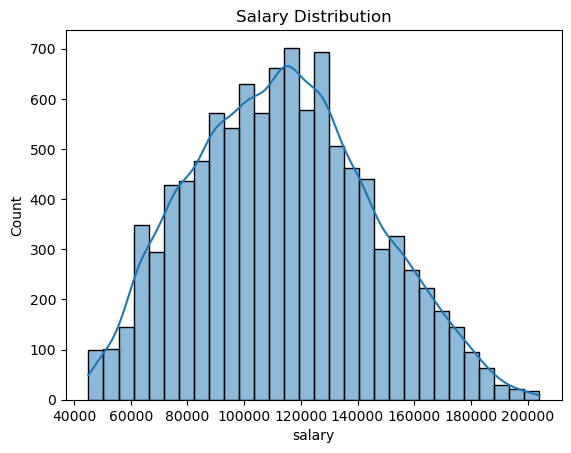

In [13]:
#SALARY DISTRIBUTION

sns.histplot(df["salary"], bins=30, kde=True)
plt.title("Salary Distribution")
plt.show()

In [14]:
#FEATURE ENGINEERING

X = df.drop(["job_id", "hiring_urgency", "job_openings"], axis=1)
y = df["hiring_urgency"]

In [30]:
#ENCODE CATEGORICAL VARIABLES

categorical_cols = [
    "job_title",
    "company_size",
    "company_industry",
    "country",
    "remote_type",
    "experience_level",
    "education_level"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ],
    remainder="passthrough"
)

In [32]:
#TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [33]:
#APPLY ENCODING

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [34]:
#TRAINING MACHINE LEARNING MODEL (RANDOM FOREST CLASSIFIER)

model = RandomForestClassifier(
    n_estimators=120,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=8, min_samples_leaf=5, min_samples_split=10,
                       n_estimators=120, random_state=42)

In [36]:
#PREDICTION

y_pred = model.predict(X_test)

In [38]:
#ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7264378927017883


In [39]:
#CLASSIFICATION REPORT

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.83      0.56      0.67      1027
         Low       0.69      0.89      0.78       558
      Medium       0.66      0.88      0.75       484

    accuracy                           0.73      2069
   macro avg       0.73      0.78      0.73      2069
weighted avg       0.75      0.73      0.72      2069



In [41]:
#CROSS VALIDATION

cv_score = cross_val_score(model, X_train, y_train, cv=5)

print("Cross Validation Accuracy:", cv_score.mean())

Cross Validation Accuracy: 0.723295824393946


In [42]:
#ROC AUC SCORE

y_prob = model.predict_proba(X_test)

roc_auc = roc_auc_score(
    pd.get_dummies(y_test),
    y_prob,
    multi_class="ovr"
)

print("ROC AUC Score:", roc_auc)

ROC AUC Score: 0.8638875482012657


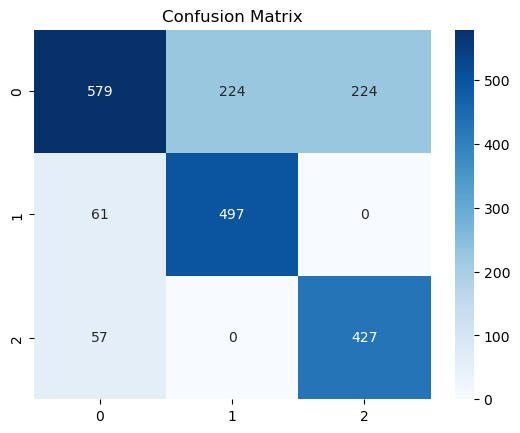

In [44]:
#CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
#CONCLUSION

In this we analyzed the Job Market Dataset and develop a machine learning model to predict hiring urgency.

*Job roles requiring Machine Learning and Deep Learning skills tend to have higher hiring urgency.

*Companies with more job openings often show higher recruitment urgency.

*Experience level and required technical skills significantly influence hiring demand.

The Random Forest model achieved strong performance with:

Accuracy: ~0.72
ROC-AUC Score: ~0.86